
# ⚙️ **PART 0 — Setup**

We use only three core libraries: **OpenCV** (`cv2`) **NumPy** and **Matplotlib** plus `ipywidgets` for sliders and dropdowns


In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

# Interactive widgets (sliders, dropdowns, buttons ...)
import ipywidgets as widgets
from ipywidgets import (interact, interactive_output, fixed,
                        IntSlider, FloatSlider, IntRangeSlider,
                        Dropdown, Checkbox)
from IPython.display import display, clear_output



# Google Colab needs this line to display ipywidgets correctly (ignored elsewhere)
try:
    from google.colab import output
    output.enable_custom_widget_manager()
    IN_COLAB = True
except Exception:
    IN_COLAB = False

%matplotlib inline
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titlesize"] = 11

print("OpenCV :", cv2.__version__)
print("NumPy  :", np.__version__)
print("Running in Colab:", IN_COLAB)

OpenCV : 5.0.0
NumPy  : 2.1.3
Running in Colab: True


### Our practice images


| Variable | What it is | Used for |
|---|---|---|
| `scene` | A 16:9 picture (960 × 540) with four **coloured corner markers** and a big letter **F** | Almost everything. The markers and the "F" make flips and rotations easy to see |
| `pattern` | A colourful pattern of the same size | Blending, masking, arithmetic |
| `photo` | A "phone photo" of a tilted paper document on a table | Perspective transformation |
| `zone` | A fine concentric-ring pattern | Showing interpolation / aliasing problems |


In [2]:
# ---------------------------------------------------------------
# IMAGE FACTORY  (no need to study this cell)
# ---------------------------------------------------------------
def make_scene(w=960, h=540):
    img = np.zeros((h, w, 3), np.uint8)
    horizon = int(h * 0.62)


    # Sky: vertical gradient (BGR colours)
    top, bot = np.array([200, 120, 40], np.float32), np.array([250, 225, 175], np.float32)
    t = np.linspace(0, 1, horizon, dtype=np.float32)[:, None, None]
    img[:horizon] = (top * (1 - t) + bot * t).astype(np.uint8)


    # Ground + hills
    img[horizon:] = (60, 140, 70)
    cv2.ellipse(img, (int(w*0.25), horizon), (int(w*0.30), 90), 0, 180, 360, (70, 120, 60), -1)
    cv2.ellipse(img, (int(w*0.75), horizon), (int(w*0.28), 70), 0, 180, 360, (80, 150, 85), -1)
    cv2.rectangle(img, (0, int(h*0.86)), (w, h), (50, 115, 60), -1)


    # Sun and clouds
    cv2.circle(img, (780, 110), 45, (60, 220, 255), -1)
    for cx, cy in [(480, 90), (540, 100), (600, 85)]:
        cv2.ellipse(img, (cx, cy), (45, 22), 0, 0, 360, (255, 255, 255), -1)

    # House
    cv2.rectangle(img, (200, 300), (400, 460), (120, 170, 235), -1)
    cv2.fillPoly(img, [np.array([(170, 300), (430, 300), (300, 200)])], (40, 50, 190))
    cv2.rectangle(img, (275, 370), (325, 460), (40, 70, 110), -1)
    cv2.rectangle(img, (220, 330), (260, 370), (255, 240, 200), -1)
    cv2.rectangle(img, (340, 330), (380, 370), (255, 240, 200), -1)

    # Tree
    cv2.rectangle(img, (610, 380), (630, 460), (30, 60, 100), -1)
    cv2.circle(img, (620, 350), 55, (40, 110, 40), -1)


    # Orientation helpers: big "F" and four coloured corner markers
    cv2.putText(img, "F", (40, 150), cv2.FONT_HERSHEY_DUPLEX, 4, (255, 255, 255), 9, cv2.LINE_AA)
    cv2.putText(img, "Lab 2", (w-190, h-25), cv2.FONT_HERSHEY_SIMPLEX, 1.2, (255, 255, 255), 3, cv2.LINE_AA)
    s = 36
    cv2.rectangle(img, (0, 0), (s, s), (0, 0, 255), -1)           # top-left     = RED
    cv2.rectangle(img, (w-s, 0), (w, s), (0, 200, 0), -1)         # top-right    = GREEN
    cv2.rectangle(img, (w-s, h-s), (w, h), (255, 0, 0), -1)       # bottom-right = BLUE
    cv2.rectangle(img, (0, h-s), (s, h), (0, 255, 255), -1)       # bottom-left  = YELLOW
    return img



scene   = make_scene()
gray    = cv2.cvtColor(scene, cv2.COLOR_BGR2GRAY)

# A few known positions in `scene` (x, y, ...) that we will use in exercises
LANDMARKS = {"sun": (780, 110, 45), "house": (170, 200, 430, 460), "tree": (565, 295, 675, 460)}

In [3]:
def make_pattern(w=960, h=540):
    y, x = np.mgrid[0:h, 0:w].astype(np.float32)
    b = 127 + 127*np.sin(x/37.0)
    g = 127 + 127*np.sin(y/29.0 + 1)
    r = 127 + 127*np.sin((x+y)/53.0 + 2)
    img = np.dstack([b, g, r]).astype(np.uint8)
    for rad, col in [(200, (255, 255, 255)), (140, (0, 0, 0)), (80, (255, 255, 255))]:
        cv2.circle(img, (w//2, h//2), rad, col, 8, cv2.LINE_AA)
    cv2.putText(img, "PATTERN", (w//2-150, h//2+15), cv2.FONT_HERSHEY_DUPLEX, 2.2, (255, 255, 255), 5, cv2.LINE_AA)
    return img


pattern = make_pattern()

In [4]:
def make_document(w=500, h=700):
    d = np.full((h, w, 3), 245, np.uint8)
    cv2.rectangle(d, (0, 0), (w-1, h-1), (60, 60, 200), 6)
    cv2.putText(d, "LAB REPORT", (60, 90), cv2.FONT_HERSHEY_DUPLEX, 1.7, (40, 40, 40), 3, cv2.LINE_AA)
    cv2.line(d, (50, 115), (w-50, 115), (40, 40, 40), 3)
    rng = np.random.RandomState(1)
    for i in range(14):
        y = 170 + i*28
        end = w - 50 - int(rng.randint(0, 120))
        cv2.line(d, (50, y), (end, y), (120, 120, 120), 6)
    cv2.circle(d, (370, 590), 60, (200, 60, 60), 4, cv2.LINE_AA)
    cv2.putText(d, "OK", (338, 605), cv2.FONT_HERSHEY_DUPLEX, 1.4, (200, 60, 60), 3, cv2.LINE_AA)
    for p in [(8, 8), (w-9, 8), (w-9, h-9), (8, h-9)]:
        cv2.circle(d, p, 7, (0, 0, 255), -1)
    return d


doc = make_document()

In [5]:
def make_photo(doc, size=(800, 700)):
    W, H = size
    rng = np.random.RandomState(0)
    table = np.full((H, W, 3), (70, 105, 150), np.uint8)
    table = np.clip(table.astype(np.int16) + rng.randint(-12, 12, (H, 1, 1)) + rng.randint(-5, 5, (H, W, 1)), 0, 255).astype(np.uint8)
    quad = np.float32([[255, 35], [605, 70], [585, 670], [150, 625]])          # TL, TR, BR, BL
    dh, dw = doc.shape[:2]
    src = np.float32([[0, 0], [dw-1, 0], [dw-1, dh-1], [0, dh-1]])
    H3 = cv2.getPerspectiveTransform(src, quad)
    warped = cv2.warpPerspective(doc, H3, (W, H))
    m = cv2.warpPerspective(np.full((dh, dw), 255, np.uint8), H3, (W, H))
    out = np.where(m[..., None] > 0, warped, table)
    return out, quad


photo, PHOTO_QUAD = make_photo(doc)       # PHOTO_QUAD = 4 true corners of the paper in the photo

In [6]:
def make_zone(n=256):
    y, x = np.mgrid[0:n, 0:n].astype(np.float32)
    r2 = (x - n/2)**2 + (y - n/2)**2
    k = np.pi / (2 * (n/2*1.41))
    return (127.5 + 127.5*np.cos(k * r2)).astype(np.uint8)


zone = make_zone()

In [7]:
print("Created: scene", scene.shape, "| pattern", pattern.shape, "| photo", photo.shape, "| zone", zone.shape)

Created: scene (540, 960, 3) | pattern (540, 960, 3) | photo (700, 800, 3) | zone (256, 256)


### Two tiny display helpers

OpenCV stores colours as **BGR** but Matplotlib expects **RGB**

These helpers convert for display only they never change your data

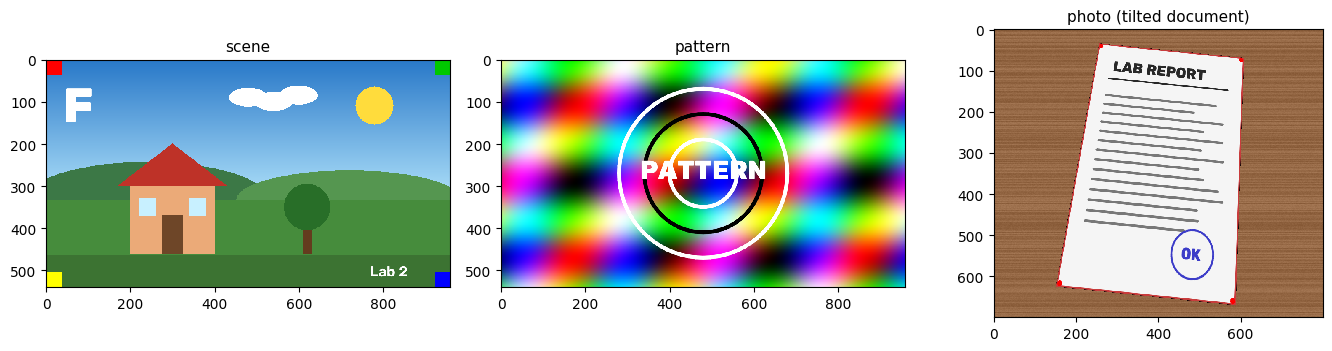

In [8]:
def show_row(images, titles=None, figsize=None, axis=True, vmax=255):
    """Show several images side by side & BGR images are converted to RGB for display"""
    n = len(images)
    figsize = figsize or (4.6 * n, 3.6)
    fig, axs = plt.subplots(1, n, figsize=figsize)
    axs = np.atleast_1d(axs)

    for i, (ax, im) in enumerate(zip(axs, images)):
        if im.ndim == 2:
            ax.imshow(im, cmap="gray", vmin=0, vmax=vmax, interpolation="nearest")
        else:
            ax.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB), interpolation="nearest")
        if titles:
            ax.set_title(titles[i])
        if not axis:
            ax.axis("off")

    plt.tight_layout()
    plt.show()

show_row([scene, pattern, photo], ["scene", "pattern", "photo (tilted document)"])


# **PART 1 — Image Geometry and Properties**

### Concept — *What is the problem?*
Before we change an image we must be able to **describe** it

If someone asks *"how big is this image?"*  the honest answer has several parts: how many rows, how many columns, how many colour values per pixel, what kind of number each value is and how much computer memory it uses

### Why is this important?
Almost every bug in image code comes from **not knowing the shape or type** of an array. Models also demand exact sizes

(e.g. `224 × 224 × 3`) and memory limits decide whether your robot's camera can process 30 frames per second




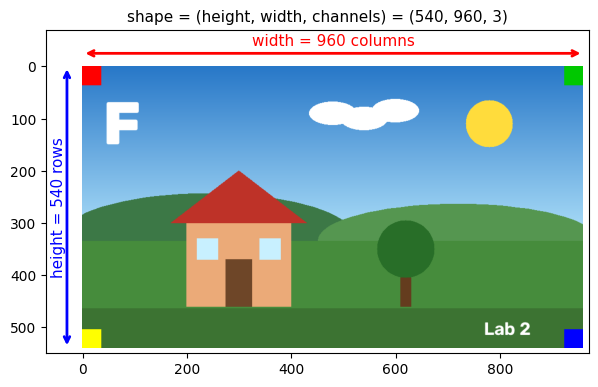

In [9]:
h, w, c = scene.shape
fig, ax = plt.subplots(figsize=(7, 4.4))

ax.imshow(cv2.cvtColor(scene, cv2.COLOR_BGR2RGB))
ax.annotate("", xy=(w, -25), xytext=(0, -25), arrowprops=dict(arrowstyle="<->", color="red", lw=2))
ax.text(w/2, -40, f"width = {w} columns", ha="center", color="red", fontsize=11)
ax.annotate("", xy=(-30, h), xytext=(-30, 0), arrowprops=dict(arrowstyle="<->", color="blue", lw=2))
ax.text(-60, h/2, f"height = {h} rows", rotation=90, va="center", color="blue", fontsize=11)
ax.set_xlim(-70, w + 10); ax.set_ylim(h + 10, -70)
ax.set_title(f"shape = (height, width, channels) = ({h}, {w}, {c})")
plt.show()

### What happens to the image?
The image is a **3-D array**: `rows × columns × channels`

Notice the order: **height first, width second**

In [10]:
img = scene                        # a shorter name to work with

print("img.shape :", img.shape)    # (height, width, channels)
print("img.dtype :", img.dtype)    # type of each number
print("img.size  :", img.size)     # total number of elements in the NumPy array = height * width * channels
print("img.nbytes:", img.nbytes)   # total memory in bytes   (uint8   uses 1 byte per value)
print("img.ndim  :", img.ndim)     # number of dimensions (3 for colour)

height, width, channels = img.shape
print()
print("Height  :", height)
print("Width   :", width)
print("Channels:", channels)
print("Number of pixels (H x W)      :", height * width)                 # Number of pixels
print("Number of values (H x W x C)  :", height * width * channels)      # Number of values

img.shape : (540, 960, 3)
img.dtype : uint8
img.size  : 1555200
img.nbytes: 1555200
img.ndim  : 3

Height  : 540
Width   : 960
Channels: 3
Number of pixels (H x W)      : 518400
Number of values (H x W x C)  : 1555200



### 🎮 Interactive Experiment — Memory calculator
Change the width, height, channels and bytes per value. Watch the memory estimate and compare it to some familiar images


In [11]:
def memory_calculator(width=1920, height=1080, channels=3, bytes_per_value=1):
    n_pixels = width * height
    n_values = n_pixels * channels
    total_bytes = n_values * bytes_per_value          # <-- the formula
    mb = total_bytes / (1024 ** 2)

    print(f"Pixels            : {n_pixels:,}")
    print(f"Values (x channels): {n_values:,}")
    print(f"Memory            : {total_bytes:,} bytes  =  {mb:,.2f} MB")

    # Compare with familiar sizes (uint8, 3 channels)
    names  = ["224x224 (model input)", "640x480 (webcam)", "1080p", "4K", "YOUR image"]
    sizes  = [224*224*3, 640*480*3, 1920*1080*3, 3840*2160*3, total_bytes]
    sizes_mb = [s / 1024**2 for s in sizes]
    fig, ax = plt.subplots(figsize=(7, 2.8))
    ax.barh(names, sizes_mb, color=["gray"]*4 + ["tab:orange"])
    ax.set_xlabel("Memory (MB)")
    ax.set_xscale("log")
    ax.set_title("Memory comparison (log scale)")
    plt.tight_layout(); plt.show()

interact(memory_calculator,
         width=IntSlider(min=32, max=7680, step=32, value=1920, description="Width"),
         height=IntSlider(min=32, max=4320, step=32, value=1080, description="Height"),
         channels=Dropdown(options=[1, 3, 4], value=3, description="Channels"),
         bytes_per_value=Dropdown(options=[("1  (uint8)", 1), ("2  (uint16)", 2), ("4  (float32)", 4), ("8  (float64)", 8)], value=1, description="Bytes/value"));

interactive(children=(IntSlider(value=1920, description='Width', max=7680, min=32, step=32), IntSlider(value=1…


#  **PART 2 — Aspect Ratio**

### What is the problem?
"My model needs a `640 × 640` input but my camera gives `1920 × 1080`
 Can I just force it?

You can but the picture will be squeezed
Circles become ovals people become thin or wide This is the **aspect ratio** problem


$$\text{Aspect Ratio} = \frac{\text{Width}}{\text{Height}}$$

For `1920 × 1080` the ratio is `1920 / 1080 = 1.78` (called **16:9**)



### Why is this important?
Shapes carry meaning & A model trained on correctly-proportioned objects will perform worse on stretched ones

### Real-world application
| Where | Why aspect ratio matters |
|---|---|
| CV preprocessing | Squeezing images before feeding a network changes object shapes |
| Object recognition | A wheel must look like a circle, not an ellipse |
| Video | 16:9 vs 4:3 screens: wrong ratio gives black bars or stretching |
| Dataset preparation | Images collected from many cameras have different ratios |

### 👀 Visual intuition
Our `scene` is 960 × 540 (16:9) exactly half of 1920 × 1080.

Original ratio : 960/540       = 1.778
Correct  ratio : 480/270     = 1.778
Incorrect ratio: 320/320     = 1.000


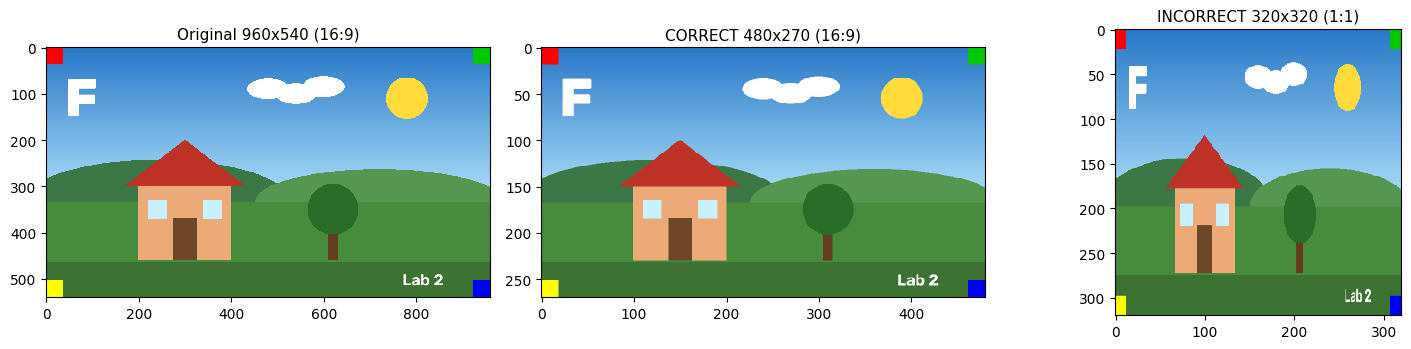

In [12]:
h, w = scene.shape[:2]
correct = cv2.resize(scene, (480, 270))      # 960x540 -> 480x270  (same ratio 16:9)
wrong   = cv2.resize(scene, (320, 320))      # 960x540 -> 320x320  (ratio 1:1)

print(f"Original ratio : {w}/{h}       = {w/h:.3f}")
print(f"Correct  ratio : 480/270     = {480/270:.3f}")
print(f"Incorrect ratio: 320/320     = {320/320:.3f}")

show_row([scene, correct, wrong],
         ["Original 960x540 (16:9)", "CORRECT 480x270 (16:9)", "INCORRECT 320x320 (1:1)"],
         figsize=(15, 3.6))

### What happened?
* **Correct:** width and height were both divided by 2 so the ratio stayed `1.78` Everything just got smaller
* **Incorrect:** width was divided by 3 but height only by 1.69 so Horizontal distances shrank more than vertical ones The sun is now an **oval** and the house is **tall and thin**

### Mathematical intuition — the rule for preserving aspect ratio
If you choose the **new width** the new height must follow:

$$\text{new_height} = \text{old_height} \times \frac{\text{new_width}}{\text{old_width}}$$


In [13]:
h, w = scene.shape[:2]

new_w = 300                              # we choose the width...
scale = new_w / w                        # how much did the width shrink?  (0.3125)
new_h = int(h * scale)                   # ...and shrink the height by the same factor

print(f"Scale factor: {scale:.4f}")
print(f"New size    : {new_w} x {new_h}  (ratio {new_w/new_h:.3f}, original {w/h:.3f})")

Scale factor: 0.3125
New size    : 300 x 168  (ratio 1.786, original 1.778)


### 🎮 Interactive Experiment — Distort the image
Move the width and height sliders **Untick "Lock aspect ratio"** to see distortion

The title turns green (OK) or red (DISTORTED) depending on whether the ratio matches the original

In [14]:
def aspect_lab(new_w=480, new_h=270, lock=False):
    h, w = scene.shape[:2]
    if lock:                                     # compute height from width
        new_h = int(round(h * new_w / w))
    out = cv2.resize(scene, (new_w, new_h))
    ok = abs(new_w / new_h - w / h) < 0.02
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
    axs[0].imshow(cv2.cvtColor(scene, cv2.COLOR_BGR2RGB)); axs[0].set_title(f"Original  {w}x{h}   ratio {w/h:.2f}")
    axs[1].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
    axs[1].set_title(f"{'OK' if ok else 'DISTORTED'}  {new_w}x{new_h}   ratio {new_w/new_h:.2f}",
                     color="green" if ok else "red")
    plt.tight_layout(); plt.show()

interact(aspect_lab,
         new_w=IntSlider(min=50, max=960, step=10, value=480, description="Width"),
         new_h=IntSlider(min=50, max=960, step=10, value=270, description="Height"),
         lock=Checkbox(value=False, description="Lock aspect ratio"));

interactive(children=(IntSlider(value=480, description='Width', max=960, min=50, step=10), IntSlider(value=270…


# **PART 3 — Image Resizing**

### What is the problem?
> "What if our image is too large for our model? Or too small to see?"

**Resizing** changes the number of pixels in an image (its width and height)

The hard part: *where do the new pixel values come from?*

### Why is this important?
* Neural networks accept **one fixed input size**
* Smaller images are processed **much faster** (half the width and height = 4× fewer pixels)
* Enlarging lets us zoom in on small details

### Real-world application
Face-recognition apps shrink photos to small fixed sizes

Satellite viewers enlarge small areas


### 👀 Visual intuition — *where do new pixels come from?*
**Downscaling** (shrinking): many old pixels must be merged into one new pixel → we lose information

**Upscaling** (enlarging): new pixels appear *between* old pixels → we must **invent** their values

```text
Original row:   [ 0 ]-----------[ 100 ]
Enlarge ×4:     [ 0 ]  [ ? ]  [ ? ]  [ ? ]  [ 100 ]
                         ↑ how do we guess the missing values?
```

The method used to guess is called **interpolation**

In [15]:
# Two known pixels: value 0 at position 0 and value 100 at position 1
# Where would a NEW pixel at position 0.25 get its value?
p0, p1, pos = 0, 100, 0.25

nearest = p0 if pos < 0.5 else p1                # copy the closest known pixel
linear  = p0 * (1 - pos) + p1 * pos              # weighted average of the two neighbours

print("Nearest-neighbour value:", nearest)       # 0
print("Linear value           :", linear)        # 25.0

Nearest-neighbour value: 0
Linear value           : 25.0


### Mathematical intuition
| Method | Idea | Looks like |
|---|---|---|
| **Nearest neighbour** | Copy the closest pixel | Blocky, sharp edges, fastest |
| **Bilinear** (`INTER_LINEAR`) | Weighted average of the **4** nearest pixels | Smooth, good default |
| **Bicubic** (`INTER_CUBIC`) | Smooth curve through **16** neighbours | Smoother, slower |
| **Area** (`INTER_AREA`) | Average of **all old pixels** covered by the new pixel | Best for **shrinking** |
| **Lanczos** (`INTER_LANCZOS4`) | Uses **64** neighbours | Highest quality enlarge, slowest |

### 👀 Visual intuition — a *tiny* image enlarged a lot
We shrink `scene` to just **16 × 9 pixels** and then enlarge it 30× Now you can literally **see** each method estimating new pixel values

tiny image shape: (9, 16, 3)


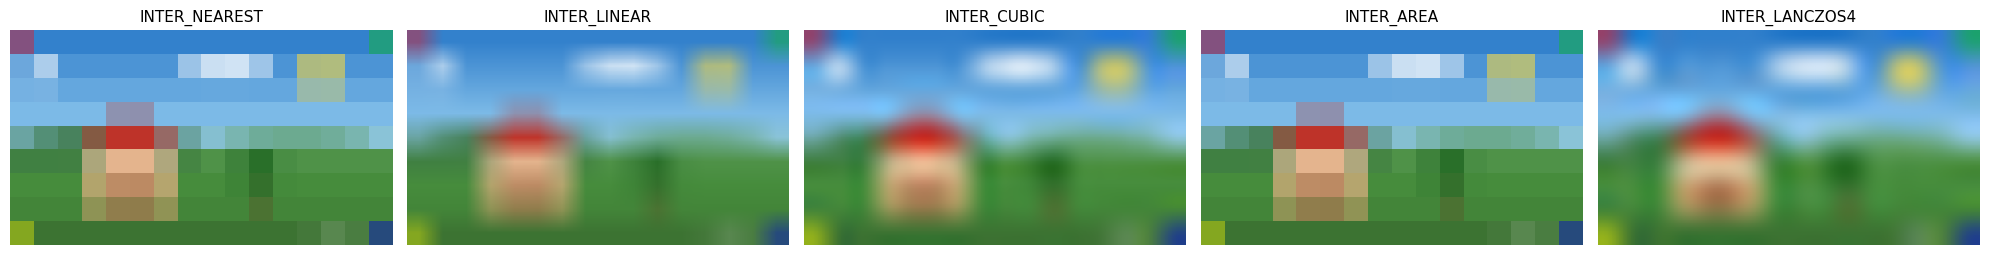

In [16]:
tiny = cv2.resize(scene, (16, 9), interpolation=cv2.INTER_AREA)       # 16 x 9 pixels only
print("tiny image shape:", tiny.shape)

methods = {
    "INTER_NEAREST":  cv2.INTER_NEAREST,
    "INTER_LINEAR":   cv2.INTER_LINEAR,
    "INTER_CUBIC":    cv2.INTER_CUBIC,
    "INTER_AREA":     cv2.INTER_AREA,
    "INTER_LANCZOS4": cv2.INTER_LANCZOS4,
}

results, names = [], []
for name, flag in methods.items():
    big = cv2.resize(tiny, (16 * 30, 9 * 30), interpolation=flag)     # enlarge 30x
    results.append(big); names.append(name)

show_row(results, names, figsize=(20, 2.6), axis=False)

### 🔎 What happened?
* `INTER_NEAREST` made visible **squares**: each old pixel became a 30 × 30 block
* `INTER_LINEAR` and `INTER_CUBIC` made smooth transitions. The in-between pixels are **averages** of their neighbours
* **No method can recover real detail.** The extra pixels are only *estimates*
* `INTER_AREA` is designed for shrinking, so for enlarging it behaves similarly to nearest

### shrinking has a different problem: *aliasing*
Below is a fine ring pattern. We shrink it to a quarter of its size using different methods.

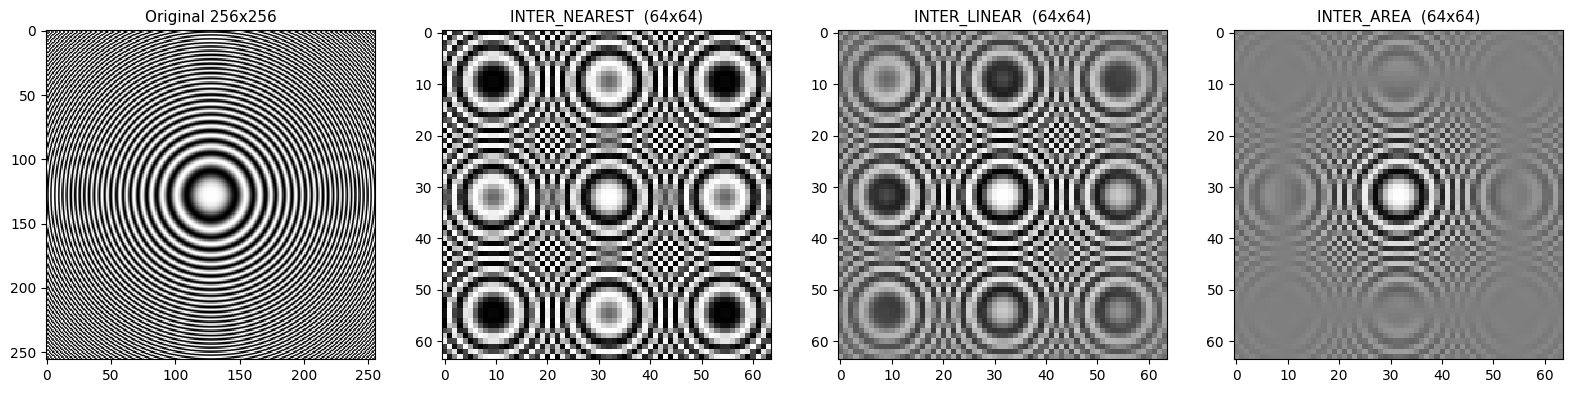

In [17]:
small_w = zone.shape[1] // 4
outs = [zone]
titles = ["Original 256x256"]
for name in ["INTER_NEAREST", "INTER_LINEAR", "INTER_AREA"]:
    outs.append(cv2.resize(zone, (small_w, small_w), interpolation=methods[name]))
    titles.append(f"{name}  (64x64)")
show_row(outs, titles, figsize=(16, 3.8))

### What happened?
`INTER_NEAREST` and `INTER_LINEAR` only look at a few pixels so they **skip** the fine detail and produce false patterns (moiré / aliasing)

`INTER_AREA` averages everything under each new pixel and gives the most faithful result

 **Rule of thumb:**

| Situation | Recommended interpolation |
|---|---|
| **Shrinking** | `INTER_AREA` |
| **Enlarging**, speed matters | `INTER_LINEAR` (default) |
| **Enlarging**, quality matters | `INTER_CUBIC` or `INTER_LANCZOS4` |

### Code Version 1: cv2.resize()

In [18]:
img = scene
resized = cv2.resize(img, (480, 270))          # <-- (WIDTH, HEIGHT)  !!! not (height, width)

print("Original:", img.shape)                  # (540, 960, 3)
print("Resized :", resized.shape)              # (270, 480, 3)  <- shape prints (height, width)

Original: (540, 960, 3)
Resized : (270, 480, 3)


### What happened? (parameters)
| Argument | Meaning |
|---|---|
| `img` | The input image |
| `(480, 270)` | **(width, height)** of the output `cv2.resize` uses `(width, height)` but `img.shape` is `(height, width)` This is the #1 beginner bug |
| `interpolation=` | (optional) How to compute new pixels Default: `cv2.INTER_LINEAR` |

### Code Version 2: scaling factors
Instead of an exact size we can say make it 50 % as big:

half  : (270, 480, 3)
double: (540, 960, 3)


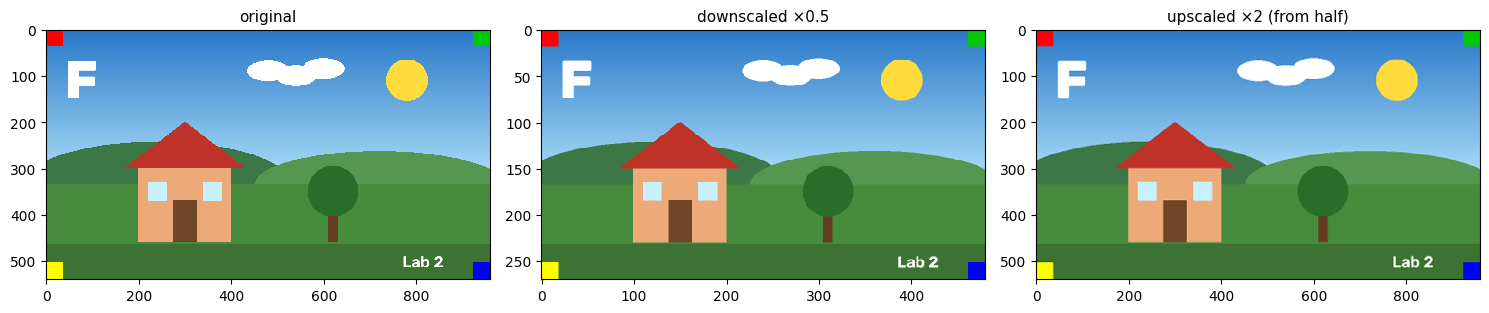

In [19]:
half   = cv2.resize(img, None, fx=0.5, fy=0.5)                              # downscale: 50 %
double = cv2.resize(half, None, fx=2.0, fy=2.0, interpolation=cv2.INTER_CUBIC)   # upscale: 200 %

print("half  :", half.shape)
print("double:", double.shape)

show_row([img, half, double], ["original", "downscaled ×0.5", "upscaled ×2 (from half)"], figsize=(15, 3.5))

half  : (378, 480, 3)
double: (869, 720, 3)


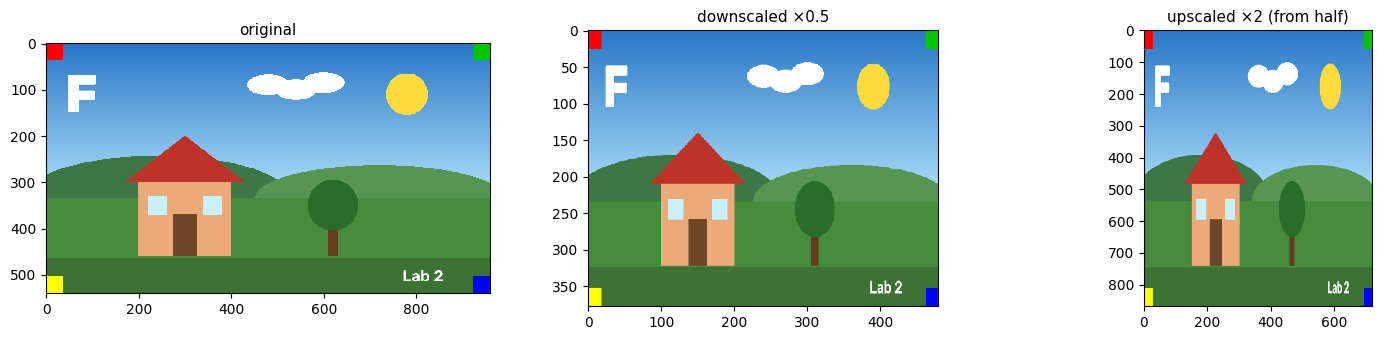

In [20]:
half   = cv2.resize(img, None, fx=0.5, fy=0.7)                              # downscale: 50 %
double = cv2.resize(half, None, fx=1.5, fy=2.3, interpolation=cv2.INTER_CUBIC)   # upscale: 200 %

print("half  :", half.shape)
print("double:", double.shape)

show_row([img, half, double], ["original", "downscaled ×0.5", "upscaled ×2 (from half)"], figsize=(15, 3.5))

###  What happened?

* `None` for the size means "compute the size from `fx` and `fy`"
* `fx` scales the **width** `fy` scales the **height** and Using the same value keeps the aspect ratio
* The last image has the **same size** as the original but looks **softer**: we threw away detail when shrinking and cannot get it back *Information lost is lost forever*



# **PART 4 — Cropping and ROI (Region of Interest)**

## What is the problem?
> "I only care about the traffic sign not the whole street so How can I cut it out?"

A **Region Of Interest (ROI)** is a rectangular part of the image

In NumPy an image is just an array so **cropping = array slicing**

## Why is this important?
Processing a small ROI is faster and removes distracting content

Almost every pipeline detects "where" first then crops the ROI for the next step

## Real-world application
* Detect a face → crop it → send to recognition.

* Crop a license plate for OCR

* Remove the car's dashboard from a front-camera image


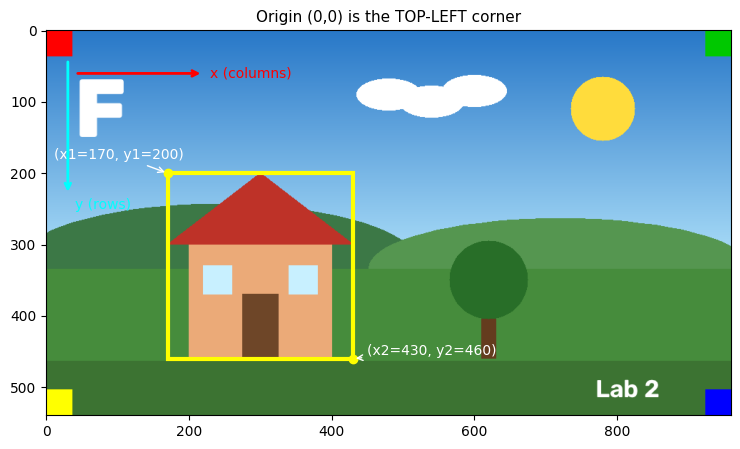

In [21]:
fig, ax = plt.subplots(figsize=(9, 5))
ax.imshow(cv2.cvtColor(scene, cv2.COLOR_BGR2RGB))
x1, y1, x2, y2 = 170, 200, 430, 460                      # the house
ax.add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="yellow", lw=3))
ax.plot([x1, x2], [y1, y2], "o", color="yellow")

ax.annotate(f"(x1={x1}, y1={y1})", (x1, y1), (x1 - 160, y1 - 20), color="white", fontsize=10,
            arrowprops=dict(arrowstyle="->", color="white"))

ax.annotate(f"(x2={x2}, y2={y2})", (x2, y2), (x2 + 20, y2 - 5), color="white", fontsize=10,
            arrowprops=dict(arrowstyle="->", color="white"))

ax.annotate("", xy=(220, 60), xytext=(40, 60), arrowprops=dict(arrowstyle="->", color="red", lw=2))
ax.text(230, 66, "x (columns)", color="red")
ax.annotate("", xy=(30, 230), xytext=(30, 40), arrowprops=dict(arrowstyle="->", color="cyan", lw=2))
ax.text(40, 250, "y (rows)", color="cyan")
ax.set_title("Origin (0,0) is the TOP-LEFT corner")
plt.show()

### Mathematical intuition
NumPy indexes **rows first then columns**:

```text
img[ y1  :  y2  ,  x1   :   x2  ]
     └ rows ┘      └ columns ┘
```
* The start index is **included** the end index is **excluded**.
* ROI width = `x2 - x1`, ROI height = `y2 - y1`


ROI shape : (260, 260, 3)
ROI width : 260
ROI height: 260


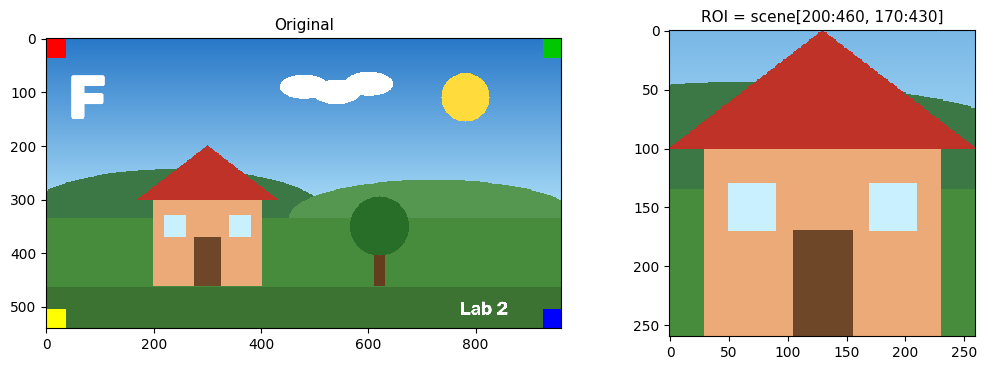

In [22]:
x1, y1, x2, y2 = 170, 200, 430, 460        # corners of the ROI (the house)

roi = scene[y1:y2, x1:x2]                  # crop = slice rows y1..y2 and columns x1..x2

print("ROI shape :", roi.shape)            # (height, width, channels) = (260, 260, 3)
print("ROI width :", x2 - x1)
print("ROI height:", y2 - y1)

show_row([scene, roi], ["Original", "ROI = scene[200:460, 170:430]"], figsize=(11, 3.8))

##  What happened?
* We did **not** call any OpenCV function as Cropping is plain NumPy slicing
* The ROI is a **smaller array**: its pixel `(0, 0)` is the original pixel `(x1, y1)` Coordinates inside an ROI start again from zero

## Interactive Experiment — ROI selector
Drag the **handles of the two range sliders**: one selects `x1…x2`, the other `y1…y2` The yellow rectangle shows the ROI and the right image shows the crop

> *Why sliders and not mouse-drag?* `cv2.selectROI()` opens a separate window which does **not** work in Google Colab. Range sliders work everywhere.

In [23]:
H, W = scene.shape[:2]

def roi_selector(x_range=(170, 430), y_range=(200, 460)):
    x1, x2 = x_range
    y1, y2 = y_range
    roi = scene[y1:y2, x1:x2]

    fig, axs = plt.subplots(1, 2, figsize=(12, 4), gridspec_kw={"width_ratios": [2, 1]})
    axs[0].imshow(cv2.cvtColor(scene, cv2.COLOR_BGR2RGB))
    axs[0].add_patch(plt.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor="yellow", lw=3))
    axs[0].set_title("Original with ROI rectangle")

    if roi.size:
        axs[1].imshow(cv2.cvtColor(roi, cv2.COLOR_BGR2RGB))
    axs[1].set_title(f"Cropped ROI  {x2-x1} x {y2-y1}")
    plt.tight_layout(); plt.show()
    print(f"x1 = {x1:4d}   y1 = {y1:4d}   x2 = {x2:4d}   y2 = {y2:4d}")
    print(f"ROI width = x2 - x1 = {x2-x1}      ROI height = y2 - y1 = {y2-y1}")
    print(f"Code:  roi = img[{y1}:{y2}, {x1}:{x2}]")

interact(roi_selector,
         x_range=IntRangeSlider(value=(170, 430), min=0, max=W, step=5, description="x1 … x2", continuous_update=False),
         y_range=IntRangeSlider(value=(200, 460), min=0, max=H, step=5, description="y1 … y2", continuous_update=False));

interactive(children=(IntRangeSlider(value=(170, 430), continuous_update=False, description='x1 … x2', max=960…

# PART 5 — ROI View vs Copy

### **What is the problem?**
> "I cropped a region and painted it red to experiment Why did my original image change too?"

When you slice a NumPy array, Python does **not** copy the pixels. It gives you a **view**: a new window onto the *same* memory

```text
 Original image memory:  [ ■■■■■■■■■■■■■■■ ]
                              ▲
 roi = img[...]  (VIEW) ──────┘   same pixels

 roi = img[...].copy()    →   [ ■■■ ]   brand-new independent pixels
```

## **Why is this important?**
* **View**: fast and memory-efficient but editing it edits the original
* **Copy**: safe but uses extra memory

Forgetting this causes some of the most confusing bugs in image processing

## **Real-world application**
Pasting an object into another image

drawing a bounding box on a crop

augmenting a patch without damaging the dataset all depend on knowing which one you hold

In [24]:
img = scene.copy()                         # work on a copy so `scene` stays clean

roi_view = img[100:200, 100:300]           # VIEW  (no copy)
roi_copy = img[100:200, 100:300].copy()    # COPY  (independent)

print("roi_view shares memory with img?", np.shares_memory(roi_view, img))   # True
print("roi_copy shares memory with img?", np.shares_memory(roi_copy, img))   # False

roi_view shares memory with img? True
roi_copy shares memory with img? False


### 🎮 Interactive Experiment — Paint the ROI did the original change?
Choose **view** or **copy** then watch the original image after painting the ROI red

In [25]:
def view_vs_copy(mode="view"):
    original = scene.copy()

    if mode == "view":
        roi = original[400:500, 170:430]                 # view
    else:
        roi = original[200:460, 170:430].copy()          # copy

    roi[:] = (0, 0, 255)                                 # paint the ROI red  (BGR)
    changed = not np.array_equal(original, scene)
    show_row([roi, original], ["The ROI after painting it red", "The ORIGINAL image afterwards"], figsize=(10, 3.6))
    print("Did the original image change?", "YES ❌" if changed else "NO ✅")

interact(view_vs_copy, mode=Dropdown(options=["view", "copy"], value="view", description="ROI type"));

interactive(children=(Dropdown(description='ROI type', options=('view', 'copy'), value='view'), Output()), _do…

## What happened?
* With a **view**, painting `roi` also painted the house in the original because they share the same pixels
* With **`.copy()`** `roi` is independent so the original is untouched.

## Useful trick — pasting is also a view assignment
Assigning into a slice **intentionally** writes into the original:

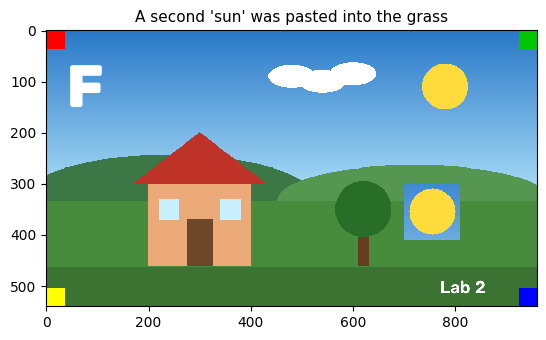

In [26]:
canvas = scene.copy()
sun_patch = scene[55:165, 725:835].copy()          # copy the sun (110 x 110)
canvas[300:410, 700:810] = sun_patch               # paste: both sides must have the SAME shape
show_row([canvas], ["A second 'sun' was pasted into the grass"], figsize=(7, 3.5))


# PART 6 — Padding and Borders

###  What is the problem?
> "My model needs a square 224 × 224 input but my image is 16:9 but
 I don't want to stretch it (Part 2) or cut parts off (cropping) What now?"

**Padding** adds extra pixels around the image and The new pixels must have *some* value The choice is the **border type**


### Why is this important?
* Make an image square or a specific size **without distortion**
* Prepare inputs for models
* Give geometric transformations (rotation, translation) extra room so corners are **not cut off**
* Keep the output the same size after some operations

### Real-world application
Object-detection models such as YOLO use **letterboxing**: resize with the aspect ratio preserved then pad the rest with grey



In [27]:
row = np.array([[1, 2, 3, 4, 5]], dtype=np.uint8)           # one row of 5 pixels

border_types = {
    "BORDER_CONSTANT":    cv2.BORDER_CONSTANT,     # fill with a fixed value
    "BORDER_REPLICATE":   cv2.BORDER_REPLICATE,    # repeat the edge pixel
    "BORDER_REFLECT":     cv2.BORDER_REFLECT,      # mirror (edge pixel repeated)
    "BORDER_REFLECT_101": cv2.BORDER_REFLECT_101,  # mirror (edge pixel NOT repeated)
    "BORDER_WRAP":        cv2.BORDER_WRAP,         # continue from the opposite side
}

for name, flag in border_types.items():
    padded = cv2.copyMakeBorder(row, 0, 0, 2, 2, flag, value=0)     # 2 pixels on left and right only
    print(f"{name:20s}", padded[0])

BORDER_CONSTANT      [0 0 1 2 3 4 5 0 0]
BORDER_REPLICATE     [1 1 1 2 3 4 5 5 5]
BORDER_REFLECT       [2 1 1 2 3 4 5 5 4]
BORDER_REFLECT_101   [3 2 1 2 3 4 5 4 3]
BORDER_WRAP          [4 5 1 2 3 4 5 1 2]


### 🔎 What happened?
```text
original              :        1 2 3 4 5
BORDER_CONSTANT       :  0 0 | 1 2 3 4 5 | 0 0      fixed colour
BORDER_REPLICATE      :  1 1 | 1 2 3 4 5 | 5 5      copy the edge pixel
BORDER_REFLECT        :  2 1 | 1 2 3 4 5 | 5 4      mirror (edge repeated)
BORDER_REFLECT_101    :  3 2 | 1 2 3 4 5 | 4 3      mirror (edge not repeated)
BORDER_WRAP           :  4 5 | 1 2 3 4 5 | 1 2      wrap around like a tiled floor
```

### 💻 Code
```python
bordered = cv2.copyMakeBorder(img, top, bottom, left, right, borderType, value=...)
```

before: (135, 240, 3)
after : (215, 360, 3)  = (135+40+40, 240+60+60, 3)


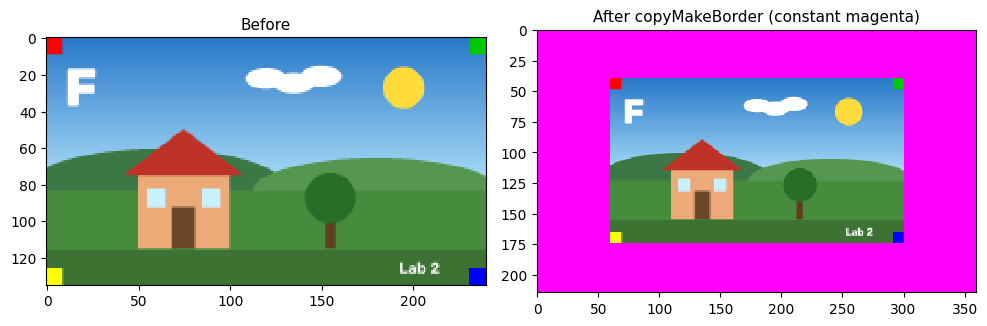

In [28]:
small = cv2.resize(scene, (240, 135), interpolation=cv2.INTER_AREA)       # small image so the border is easy to see

bordered = cv2.copyMakeBorder(small,
                              top=40, bottom=40, left=60, right=60,       # pixels to add on each side
                              borderType=cv2.BORDER_CONSTANT,
                              value=(255, 0, 255))                        # magenta (BGR) - only used with CONSTANT

print("before:", small.shape)
print("after :", bordered.shape, " = (135+40+40, 240+60+60, 3)")
show_row([small, bordered], ["Before", "After copyMakeBorder (constant magenta)"], figsize=(10, 3.4))

### What happened? (parameters)
| Parameter | Meaning |
|---|---|
| `top, bottom, left, right` | **Number of pixels** to add on each side |
| `borderType` | How the new pixels are filled (the five types above) |
| `value` | Colour used **only** for `BORDER_CONSTANT` |

New size = `(height + top + bottom, width + left + right)`

In [29]:
def border_lab(border="BORDER_CONSTANT", top=40, bottom=40, left=60, right=60, color="#ff00ff"):
    # colour picker gives "#rrggbb"  ->  OpenCV needs BGR
    r, g, b = int(color[1:3], 16), int(color[3:5], 16), int(color[5:7], 16)
    out = cv2.copyMakeBorder(small, top, bottom, left, right, border_types[border], value=(b, g, r))
    show_row([small, out], [f"Before {small.shape[1]}x{small.shape[0]}", f"{border}  →  {out.shape[1]}x{out.shape[0]}"],
             figsize=(11, 3.6))

interact(border_lab,
         border=Dropdown(options=list(border_types.keys()), value="BORDER_REFLECT_101", description="Type"),
         top=IntSlider(min=0, max=100, value=40, description="Top"),
         bottom=IntSlider(min=0, max=100, value=40, description="Bottom"),
         left=IntSlider(min=0, max=100, value=60, description="Left"),
         right=IntSlider(min=0, max=100, value=60, description="Right"),
         color=widgets.ColorPicker(value="#ff00ff", description="Colour"));

interactive(children=(Dropdown(description='Type', index=3, options=('BORDER_CONSTANT', 'BORDER_REPLICATE', 'B…

### Real application — Letterboxing (resize **without** distortion)
Goal: turn a 960 × 540 image into exactly **224 × 224** no stretching:

```text
Step 1: resize so the LONGER side = 224   →  224 × 126
Step 2: pad the SHORTER side to 224       →  (224-126)/2 = 49 pixels top and bottom
```

resized: (126, 224, 3)  padded: (224, 224, 3)


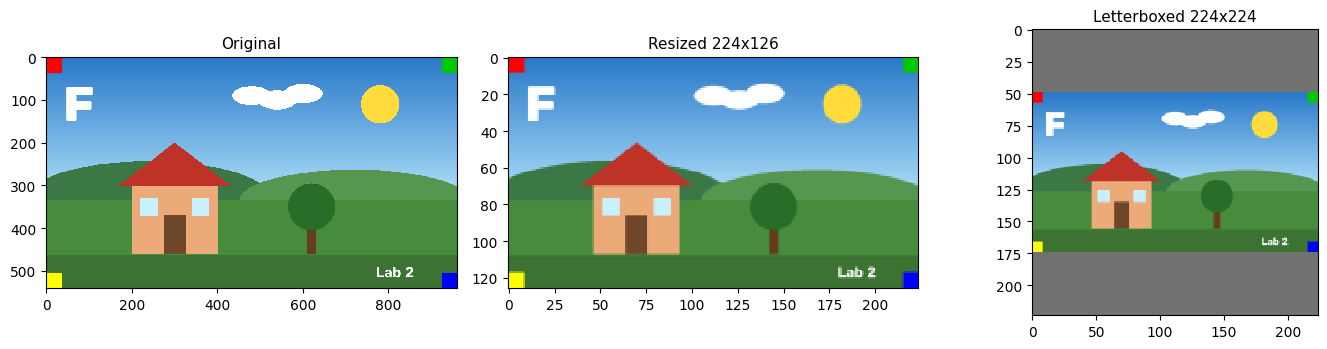

In [30]:
target = 224
h, w = scene.shape[:2]

scale = target / max(h, w)                                   # shrink the longer side to 224
new_w, new_h = int(w * scale), int(h * scale)
resized = cv2.resize(scene, (new_w, new_h), interpolation=cv2.INTER_AREA)

pad_total = target - new_h                                   # extra rows needed
top = pad_total // 2
bottom = pad_total - top                                     # handles odd numbers

square = cv2.copyMakeBorder(resized, top, bottom, 0, 0, cv2.BORDER_CONSTANT, value=(114, 114, 114))   # grey

print("resized:", resized.shape, " padded:", square.shape)
show_row([scene, resized, square], ["Original", f"Resized {new_w}x{new_h}", "Letterboxed 224x224"], figsize=(14, 3.6))


# **PART 7 — Flipping**

### What is the problem?
> "I have photos of a car facing left Can I get 'new' photos of cars facing right without taking new pictures?"

**Flipping** mirrors the image: left ↔ right or top ↔ bottom No pixel value is changed Only the **positions** move

### Why is this important?
Flipping is one of the cheapest and most popular forms of **data augmentation**: showing a model mirrored copies teaches it that a cat facing left is still a cat

### Real-world application
Selfie cameras mirror your preview

Training pipelines randomly flip images

Some medical and robot-vision systems must *not* flip: a mirrored "R" or a left/right arm label changes meaning



### Code
```python
flipped = cv2.flip(img, flipCode)
```
| `flipCode` | Effect |
|---|---|
| `1` | Horizontal flip (mirror left ↔ right) |
| `0` | Vertical flip (top ↔ bottom) |
| `-1` | Both |

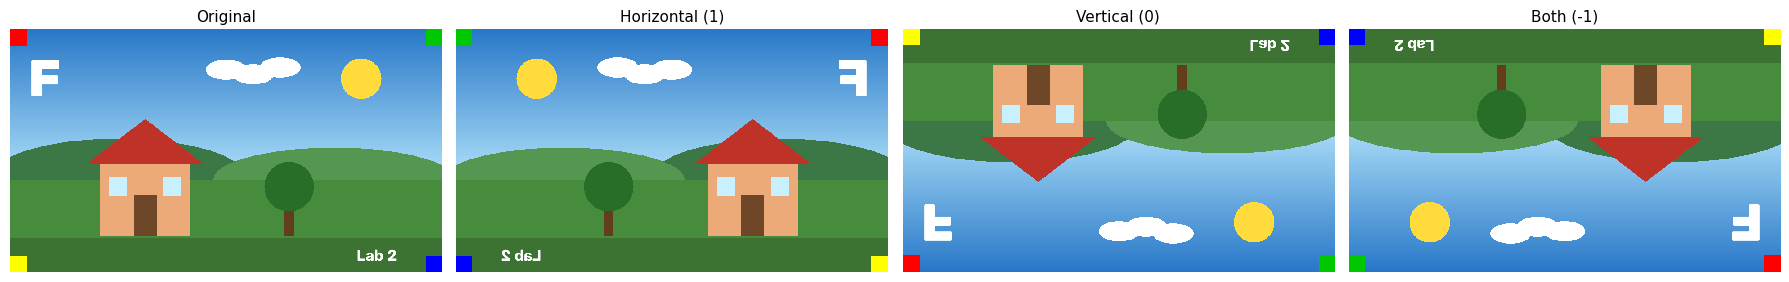

flip(1) == img[:, ::-1] ? True
flip(0) == img[::-1]    ? True


In [31]:
flip_h = cv2.flip(scene, 1)       # mirror left <-> right
flip_v = cv2.flip(scene, 0)       # mirror top <-> bottom
flip_b = cv2.flip(scene, -1)      # both (same as rotating 180 degrees)

show_row([scene, flip_h, flip_v, flip_b],
         ["Original", "Horizontal (1)", "Vertical (0)", "Both (-1)"], figsize=(18, 2.9), axis=False)

# Flipping is just reversing an axis in NumPy!
print("flip(1) == img[:, ::-1] ?", np.array_equal(flip_h, scene[:, ::-1]))
print("flip(0) == img[::-1]    ?", np.array_equal(flip_v, scene[::-1]))

### 🎮 Interactive Experiment — Flip viewer + augmentation

In [32]:
flip_codes = {"Original": None, "Horizontal (1)": 1, "Vertical (0)": 0, "Both (-1)": -1}

def flip_lab(mode="Horizontal (1)"):
    code_ = flip_codes[mode]
    out = scene if code_ is None else cv2.flip(scene, code_)
    show_row([scene, out], ["Original", mode], figsize=(11, 3.6))
    print("flipCode =", code_)

interact(flip_lab, mode=Dropdown(options=list(flip_codes.keys()), value="Horizontal (1)", description="Flip"));

interactive(children=(Dropdown(description='Flip', index=1, options=('Original', 'Horizontal (1)', 'Vertical (…


# **PART 8 — Translation**

##  Concept — *What is the problem?*
> "How can we move an image left, right, up or down?"

**Translation** shifts every pixel by the same amount: `tx` pixels horizontally and `ty` pixels vertically.

## Why is this important?
* Align two images that were taken from slightly different positions.
* Augment data (a cat does not have to be in the centre).
* Simulate camera shake and test robustness.


### 👀 Visual intuition + 💡 Mathematical intuition
Every pixel at `(x, y)` moves to `(x', y')`:

$$x' = x + t_x \qquad y' = y + t_y$$

Positive `tx` → move **right**. Positive `ty` → move **down** (remember: y grows downward!).

Computers write this as a **matrix** so that many transformations can use the *same* function:

$$\begin{bmatrix} x' \\ y' \end{bmatrix} = \begin{bmatrix} 1 & 0 & t_x \\ 0 & 1 & t_y \end{bmatrix} \begin{bmatrix} x \\ y \\ 1 \end{bmatrix}$$

Multiplying this out gives exactly `x' = 1·x + 0·y + tx·1` and `y' = 0·x + 1·y + ty·1`

 The extra "1" lets the matrix include the shift. Check it with numbers:

In [33]:
tx, ty = 30, 20
M = np.float32([[1, 0, tx],
                [0, 1, ty]])

point = np.array([100, 50, 1])          # the pixel (x=100, y=50) written with the extra 1
print("M @ point =", M @ point)         # -> [130, 70]  = (100+30, 50+20)

M @ point = [130.  70.]


### 💻 Code
```python
M = np.float32([[1, 0, tx],
                [0, 1, ty]])
translated = cv2.warpAffine(img, M, (width, height))
```

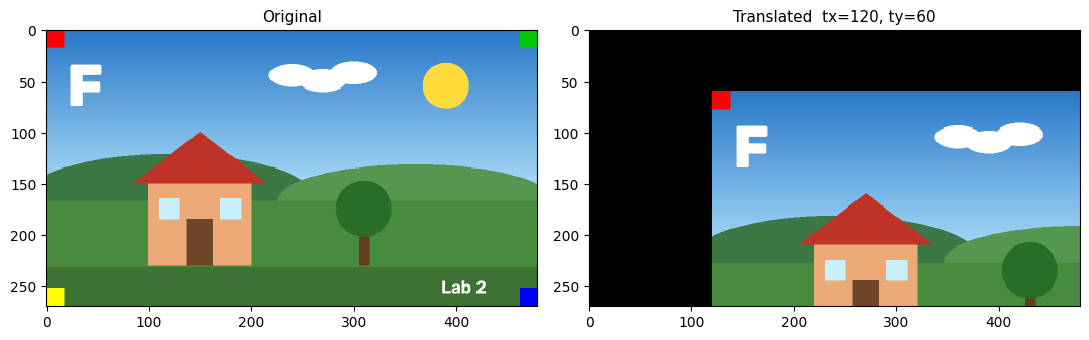

In [34]:
base = cv2.resize(scene, (480, 270), interpolation=cv2.INTER_AREA)    # half-size image keeps widgets fast
h, w = base.shape[:2]

tx, ty = 120, 60
M = np.float32([[1, 0, tx],
                [0, 1, ty]])

translated = cv2.warpAffine(base, M, (w, h))        # output size is (WIDTH, HEIGHT) again!
show_row([base, translated], ["Original", f"Translated  tx={tx}, ty={ty}"], figsize=(11, 3.6))

###  What happened? (line by line)
| Code | Meaning |
|---|---|
| `M = np.float32([[1,0,tx],[0,1,ty]])` | The 2×3 transformation matrix The first two columns are `[[1,0],[0,1]]` ("don't rotate / scale") and the last column is the shift |
| `cv2.warpAffine(img, M, (w, h))` | Create a new image of size `(w, h)` for each output pixel look up where it comes from in the input using `M` |
| `(w, h)` | Output **(width, height)**  you decide the canvas size |

**What about the empty regions?**

 The image moved right/down but the top and left strips of the canvas have no source pixels

OpenCV fills them with black by default (`borderMode=cv2.BORDER_CONSTANT`)The pixels that moved past the canvas edge are **lost**


In [35]:
import matplotlib.patches as patches

border_modes = {"BORDER_CONSTANT (black)": cv2.BORDER_CONSTANT,
                "BORDER_REPLICATE": cv2.BORDER_REPLICATE,
                "BORDER_REFLECT": cv2.BORDER_REFLECT}

def translation_lab(tx=100, ty=50, border="BORDER_CONSTANT (black)", expand=False):
    h, w = base.shape[:2]
    if expand:                                          # canvas grows so nothing is lost
        canvas = (w + abs(tx), h + abs(ty))
        M = np.float32([[1, 0, max(tx, 0)], [0, 1, max(ty, 0)]])
        frame = (max(-tx, 0), max(-ty, 0)); moved_at = (max(tx, 0), max(ty, 0))
    else:
        canvas = (w, h)
        M = np.float32([[1, 0, tx], [0, 1, ty]])
        frame = (0, 0); moved_at = (tx, ty)
    out = cv2.warpAffine(base, M, canvas, borderMode=border_modes[border])

    fig, axs = plt.subplots(1, 2, figsize=(12, 4))
    axs[0].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB))
    axs[0].set_title(f"Result  (canvas {canvas[0]}x{canvas[1]})")
    # coordinate view
    ax = axs[1]
    ax.add_patch(patches.Rectangle((0, 0), canvas[0], canvas[1], fill=False, edgecolor="black", lw=2))
    ax.add_patch(patches.Rectangle(frame, w, h, fill=False, edgecolor="tab:blue", ls="--", lw=2))
    ax.add_patch(patches.Rectangle(moved_at, w, h, facecolor="tab:orange", alpha=0.35, edgecolor="tab:orange", lw=2))
    ax.annotate("", xy=moved_at, xytext=frame, arrowprops=dict(arrowstyle="->", lw=2, color="red"))
    sx, sy = 390, 55                                     # the sun's centre in this half-size image
    ax.plot(sx + frame[0], sy + frame[1], "o", color="tab:blue"); ax.plot(sx + moved_at[0], sy + moved_at[1], "o", color="red")
    ax.set_xlim(-w * 0.6, w * 1.7); ax.set_ylim(h * 1.7, -h * 0.6); ax.set_aspect("equal")
    ax.set_title(f"Coordinates: black = canvas, blue dashed = original, orange = moved\nsun: ({sx},{sy}) → ({sx+tx},{sy+ty})")
    plt.tight_layout(); plt.show()
    print("M =", M.tolist())

interact(translation_lab,
         tx=IntSlider(min=-300, max=300, step=10, value=100, description="TX"),
         ty=IntSlider(min=-200, max=200, step=10, value=50, description="TY"),
         border=Dropdown(options=list(border_modes.keys()), value="BORDER_CONSTANT (black)", description="Empty px"),
         expand=Checkbox(value=False, description="Expand canvas"));

interactive(children=(IntSlider(value=100, description='TX', max=300, min=-300, step=10), IntSlider(value=50, …


# PART 9 — Rotation

### What is the problem?
> "A drone camera is tilted by 15° How do we straighten the picture?"

### Why is this important?
* Correct tilted cameras and scanned pages
* Create rotated training examples (objects appear at any angle)
* Align images before comparing them

### Real-world application
Phone photos auto-rotate when you turn the phone



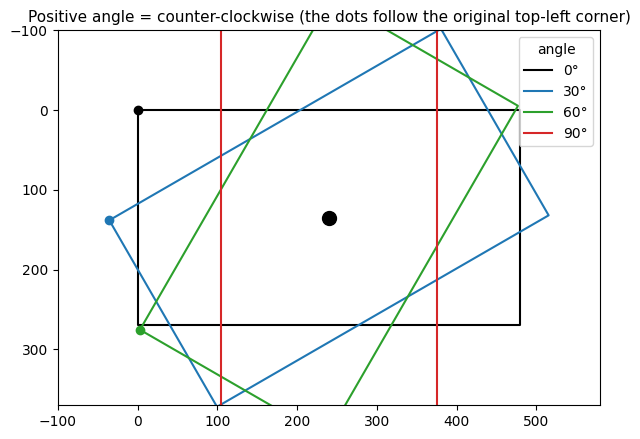

In [36]:
h, w = base.shape[:2]
corners = np.float32([[0, 0], [w, 0], [w, h], [0, h]])           # TL, TR, BR, BL
center = (w / 2, h / 2)

fig, ax = plt.subplots(figsize=(7, 5))
for angle, col in zip([0, 30, 60, 90], ["black", "tab:blue", "tab:green", "tab:red"]):
    Mr = cv2.getRotationMatrix2D(center, angle, 1.0)
    pts = cv2.transform(corners[None], Mr)[0]                    # apply the transform to the 4 corners
    closed = np.vstack([pts, pts[0]])
    ax.plot(closed[:, 0], closed[:, 1], color=col, label=f"{angle}°")
    ax.plot(*pts[0], "o", color=col)                             # follow the top-left corner
ax.plot(*center, "ko", ms=10)
ax.set_xlim(-100, w + 100); ax.set_ylim(h + 100, -100); ax.set_aspect("equal"); ax.legend(title="angle")
ax.set_title("Positive angle = counter-clockwise (the dots follow the original top-left corner)")
plt.show()

## Mathematical intuition
Rotating a point by an angle θ around the **origin**:

$$x' = x\cos\theta - y\sin\theta \qquad y' = x\sin\theta + y\cos\theta$$

To rotate around another **centre** `(cx, cy)`:

 (1) move the centre to the origin, (2) rotate, (3) move back

  OpenCV packs all three steps into one 2×3 matrix. It also includes an optional **scale**

## First the easy case: 90° steps with `cv2.rotate`
Rotating by exactly 90°, 180° or 270° needs **no interpolation**: pixels are just rearranged



**30°, 45°, 37°**  -->
pixels don't align perfectly -->
interpolation needed




**For multiples of 90°**  --> 90°, 180°, 270° -->
pixels align exactly -->
rearrangement only

original : (270, 480, 3)
90° cw   : (480, 270, 3)  ← width and height swapped
180°     : (270, 480, 3)


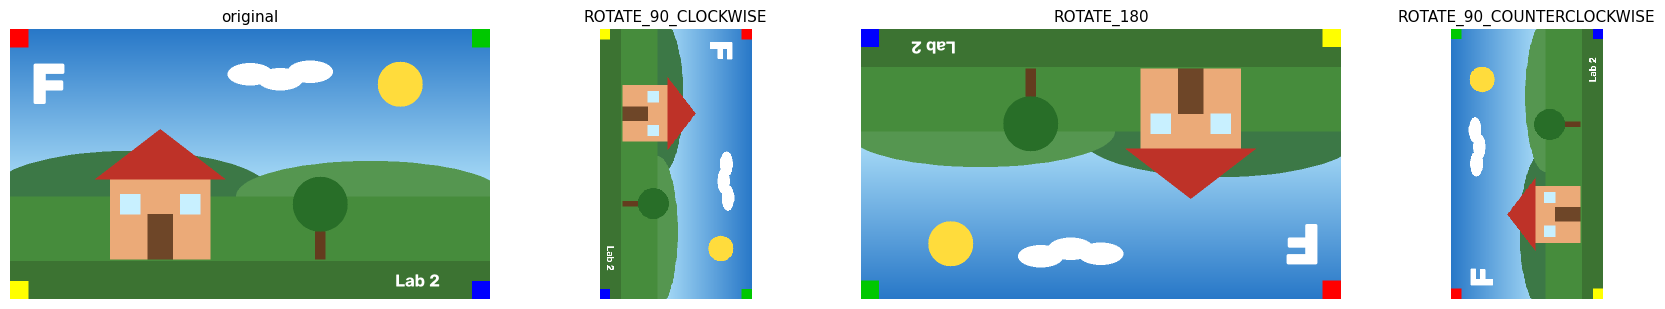

In [37]:
r90cw  = cv2.rotate(base, cv2.ROTATE_90_CLOCKWISE)
r180   = cv2.rotate(base, cv2.ROTATE_180)
r90ccw = cv2.rotate(base, cv2.ROTATE_90_COUNTERCLOCKWISE)

print("original :", base.shape)
print("90° cw   :", r90cw.shape, " ← width and height swapped")
print("180°     :", r180.shape)
show_row([base, r90cw, r180, r90ccw], ["original", "ROTATE_90_CLOCKWISE", "ROTATE_180", "ROTATE_90_COUNTERCLOCKWISE"], figsize=(18, 3.2), axis=False)

### 🧠 Arbitrary angles
For any other angle we need a transformation matrix:
```python
M = cv2.getRotationMatrix2D(center, angle, scale)
rotated = cv2.warpAffine(img, M, (w, h))
```

Rotation matrix M:
 [[  0.866   0.5   -35.346]
 [ -0.5     0.866 138.087]]


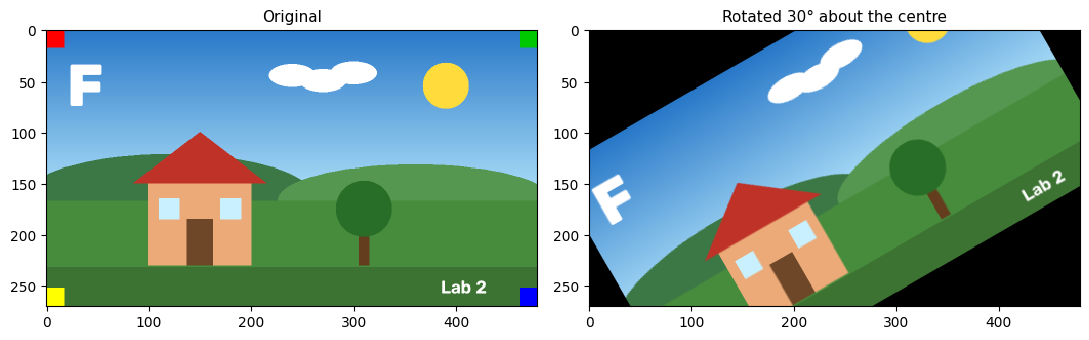

In [38]:
h, w = base.shape[:2]
center = (w // 2, h // 2)                   # (x, y) of the pivot point: here the image centre
angle  = 30                                 # degrees, positive = counter-clockwise
scale  = 1.0                                # 1.0 = keep the size

M = cv2.getRotationMatrix2D(center, angle, scale)
print("Rotation matrix M:\n", M.round(3))

rotated = cv2.warpAffine(base, M, (w, h))
show_row([base, rotated], ["Original", f"Rotated {angle}° about the centre"], figsize=(11, 3.6))